# 05. Phân tích nhóm hành khách

So sánh tỷ lệ hài lòng theo giới tính, loại khách hàng, mục đích bay và hạng vé.

## Đọc dữ liệu

Trong dữ liệu sạch, `satisfaction_binary` bằng 1 nếu hành khách hài lòng, bằng 0 nếu trung lập hoặc không hài lòng.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/airline_clean.csv")

## Tính tỷ lệ hài lòng

Các nhóm đều dùng cùng cách tính nên viết một hàm để dùng lại. `count` đếm số người có nhãn, `sum` đếm số người hài lòng. Vì nhãn chỉ có 0 và 1, `mean × 100` chính là phần trăm hài lòng trong từng nhóm.

In [2]:
def tinh_ty_le(col):
    bang = df.groupby(col)["satisfaction_binary"].agg(["count", "sum", "mean"])
    bang.columns = ["tong", "hai_long", "ty_le"]
    bang["ty_le"] = bang["ty_le"] * 100
    return bang

## Theo giới tính

Xem tỷ lệ hài lòng của nam và nữ. Phần kiểm định chênh lệch được làm ở notebook 09.

In [3]:
gender = tinh_ty_le("Gender")
print(gender.round(2))

         tong  hai_long  ty_le
Gender                        
Female  65899     28269  42.90
Male    63981     28159  44.01


## Theo loại khách hàng

So sánh khách trung thành và khách không trung thành. Hai nhóm có quy mô khác nhau nên cần đọc tỷ lệ cùng với số lượng.

                     tong  hai_long  ty_le
Customer Type                             
Loyal Customer     106100     50728  47.81
disloyal Customer   23780      5700  23.97


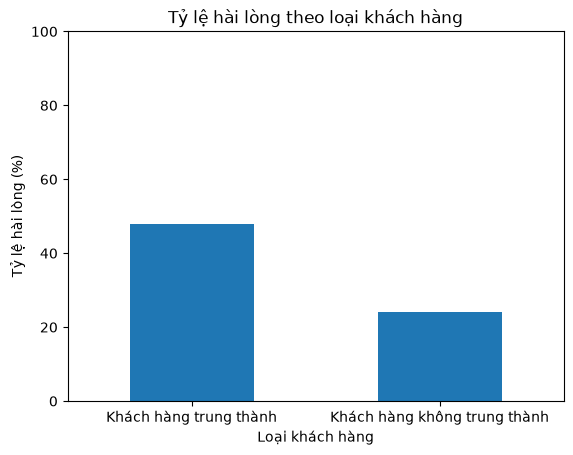

In [4]:
customer = tinh_ty_le("Customer Type")
print(customer.round(2))

customer["ty_le"].plot(kind="bar")
plt.title("Tỷ lệ hài lòng theo loại khách hàng")
plt.ylabel("Tỷ lệ hài lòng (%)")
plt.xlabel("Loại khách hàng")
plt.xticks([0, 1], ["Khách hàng trung thành", "Khách hàng không trung thành"], rotation=0)
plt.ylim(0, 100)
plt.show()

## Theo mục đích chuyến đi

So sánh khách bay công tác với khách bay cá nhân.

                  tong  hai_long  ty_le
Type of Travel                         
Business travel  89693     52356  58.37
Personal Travel  40187      4072  10.13


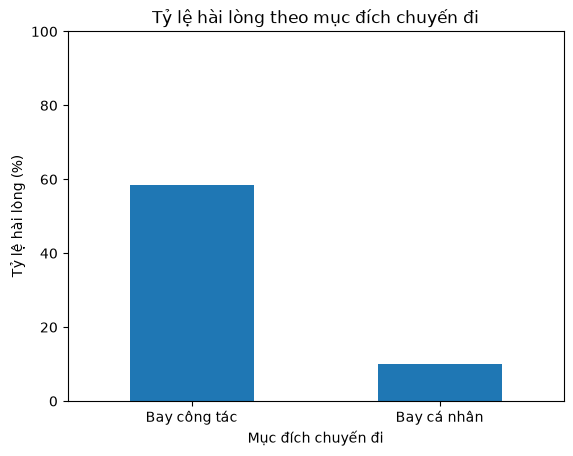

In [5]:
travel = tinh_ty_le("Type of Travel")
print(travel.round(2))

travel["ty_le"].plot(kind="bar")
plt.title("Tỷ lệ hài lòng theo mục đích chuyến đi")
plt.ylabel("Tỷ lệ hài lòng (%)")
plt.xlabel("Mục đích chuyến đi")
plt.xticks([0, 1], ["Bay công tác", "Bay cá nhân"], rotation=0)
plt.ylim(0, 100)
plt.show()

## Theo hạng vé

Sắp xếp hạng vé theo thứ tự Business, Eco Plus, Eco. Các biểu đồ đều dùng trục tung từ 0 đến 100%.

           tong  hai_long  ty_le
Class                           
Business  62160     43166  69.44
Eco Plus   9411      2319  24.64
Eco       58309     10943  18.77


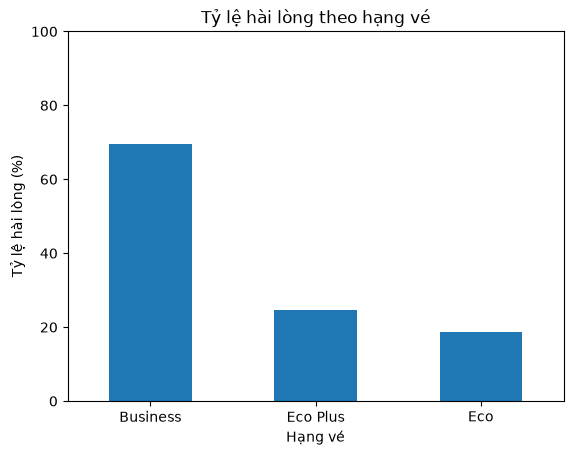

In [6]:
class_summary = tinh_ty_le("Class")
class_summary = class_summary.reindex(["Business", "Eco Plus", "Eco"])
print(class_summary.round(2))

class_summary["ty_le"].plot(kind="bar")
plt.title("Tỷ lệ hài lòng theo hạng vé")
plt.ylabel("Tỷ lệ hài lòng (%)")
plt.xlabel("Hạng vé")
plt.xticks([0, 1, 2], ["Business", "Eco Plus", "Eco"], rotation=0)
plt.ylim(0, 100)
plt.show()

## Nhận xét

Khách trung thành có tỷ lệ hài lòng 47,81%, cao hơn nhóm không trung thành (23,97%). Chênh lệch theo mục đích bay khá rõ: khách bay công tác đạt 58,37%, còn khách bay cá nhân là 10,13%.

Business có tỷ lệ hài lòng cao nhất trong ba hạng vé, đạt 69,44%. Eco Plus đạt 24,64% và Eco đạt 18,77%. Tỷ lệ theo giới tính gần nhau hơn: nữ 42,90%, nam 44,01%.

Các bảng xét riêng từng đặc điểm, chưa tính ảnh hưởng đồng thời của các yếu tố khác. Nếu đổi dữ liệu, cần cập nhật lại nhận xét.

Kết quả chỉ mô tả mẫu Airline Passenger Satisfaction. Chưa thể suy rộng cho mọi hành khách hay kết luận một đặc điểm là nguyên nhân làm khách hài lòng hơn. Notebook này chưa thực hiện kiểm định; xem phần 09.